In [1]:
# ==========================================
# 1. IMPORTS AND PROJECT CONFIGURATION
# ==========================================

from pathlib import Path
import random
import numpy as np
import pandas as pd
import torch

# Project root
PROJECT_ROOT = Path(
    r"D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L"
)

# Required directories and files
MODEL_DIR = PROJECT_ROOT / "results" / "models"

GRADCAM_DIR = (
    PROJECT_ROOT / "results" / "explanations" / "gradcam"
)

IG_DIR = (
    PROJECT_ROOT / "results" / "explanations" / "integrated_gradients"
)

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"

PREDICTIONS_PATH = (
    PROJECT_ROOT / "results" / "metrics" / "combined_test_predictions.csv"
)

FOLDS_PATH = (
    PROJECT_ROOT / "data" / "processed" / "folds.csv"
)

OUTPUT_DIR = (
    PROJECT_ROOT / "results" / "metrics" / "faithfulness_analysis"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Experiment configuration
SEED = 42

CLASS_NAMES = ["plain", "satin", "twill"]

IMAGE_SIZE = 224
PATCH_SIZE = 16

# Reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Device
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)
print("Project root:", PROJECT_ROOT)

print("\n--- Checking required directories ---")

required_directories = {
    "Model directory": MODEL_DIR,
    "Grad-CAM directory": GRADCAM_DIR,
    "Integrated Gradients directory": IG_DIR,
    "Raw image directory": RAW_DATA_DIR,
}

for name, path in required_directories.items():
    print(f"{name}: {'FOUND' if path.exists() else 'NOT FOUND'}")

print("\n--- Checking required files ---")

required_files = {
    "Combined predictions": PREDICTIONS_PATH,
    "Fold assignments": FOLDS_PATH,
}

for name, path in required_files.items():
    print(f"{name}: {'FOUND' if path.exists() else 'NOT FOUND'}")

print("\n--- Checking model checkpoints ---")

for fold in range(1, 6):
    checkpoint_path = MODEL_DIR / f"resnet18_fold{fold}.pth"

    if checkpoint_path.exists():
        size_mb = checkpoint_path.stat().st_size / (1024 ** 2)
        print(f"Fold {fold}: FOUND ({size_mb:.2f} MB)")
    else:
        print(f"Fold {fold}: NOT FOUND")

# Inspect prediction CSV
print("\n--- Combined prediction dataset ---")

if PREDICTIONS_PATH.exists():
    predictions_df = pd.read_csv(PREDICTIONS_PATH)

    print("Shape:", predictions_df.shape)
    print("\nColumns:")
    print(predictions_df.columns.tolist())

    print("\nFirst five records:")
    display(predictions_df.head())

# Inspect fold assignments
print("\n--- Fold assignment dataset ---")

if FOLDS_PATH.exists():
    folds_df = pd.read_csv(FOLDS_PATH)

    print("Shape:", folds_df.shape)
    print("\nColumns:")
    print(folds_df.columns.tolist())

    display(folds_df.head())

# Inspect original fabric images
print("\n--- Original image files ---")

if RAW_DATA_DIR.exists():
    image_extensions = {".jpg", ".jpeg", ".png"}

    image_files = [
        path for path in RAW_DATA_DIR.rglob("*")
        if path.is_file() and path.suffix.lower() in image_extensions
    ]

    print("Number of image files found:", len(image_files))
    print("Sample image paths:")

    for path in image_files[:5]:
        print(path)

Device: cpu
Project root: D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L

--- Checking required directories ---
Model directory: FOUND
Grad-CAM directory: FOUND
Integrated Gradients directory: FOUND
Raw image directory: FOUND

--- Checking required files ---
Combined predictions: FOUND
Fold assignments: FOUND

--- Checking model checkpoints ---
Fold 1: FOUND (42.72 MB)
Fold 2: FOUND (42.72 MB)
Fold 3: FOUND (42.72 MB)
Fold 4: FOUND (42.72 MB)
Fold 5: FOUND (42.72 MB)

--- Combined prediction dataset ---
Shape: (130, 6)

Columns:
['image_filename', 'actual_class', 'predicted_class', 'confidence', 'fold', 'correct']

First five records:


,image_filename,actual_class,predicted_class,confidence,fold,correct
0,W006.jpg,twill,twill,0.970566,1,True
1,W007.jpg,twill,twill,0.698218,1,True
2,W008.jpg,twill,twill,0.977882,1,True
3,W009.jpg,twill,twill,0.992629,1,True
4,W010.jpg,twill,twill,0.995661,1,True



--- Fold assignment dataset ---
Shape: (130, 4)

Columns:
['image_filename', 'Texture', 'group_id', 'test_fold']


,image_filename,Texture,group_id,test_fold
0,W001.jpg,twill,10,2
1,W002.jpg,twill,10,2
2,W003.jpg,twill,10,2
3,W004.jpg,twill,10,2
4,W005.jpg,twill,10,2



--- Original image files ---
Number of image files found: 260
Sample image paths:
D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\data\raw\archive\W001.jpg
D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\data\raw\archive\W002.jpg
D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\data\raw\archive\W003.jpg
D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\data\raw\archive\W004.jpg
D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\data\raw\archive\W005.jpg


Match images, folds, and explanation maps

In [2]:
# ==========================================
# 2. MATCH IMAGES, FOLDS AND EXPLANATION MAPS
# ==========================================

# Merge original predictions with fold assignments
faithfulness_df = predictions_df.merge(
    folds_df,
    on="image_filename",
    how="inner",
    validate="one_to_one"
)

# Verify fold assignments
faithfulness_df["fold_match"] = (
    faithfulness_df["fold"] == faithfulness_df["test_fold"]
)

# Verify actual classes
faithfulness_df["class_match"] = (
    faithfulness_df["actual_class"].str.lower()
    == faithfulness_df["Texture"].str.lower()
)

print("--- Dataset matching ---")
print("Matched records:", len(faithfulness_df))
print("Unique images:", faithfulness_df["image_filename"].nunique())
print("Fold assignments match:", faithfulness_df["fold_match"].all())
print("Actual classes match:", faithfulness_df["class_match"].all())

# Find all original image paths by filename
image_extensions = {".jpg", ".jpeg", ".png"}

all_image_paths = [
    path
    for path in RAW_DATA_DIR.rglob("*")
    if path.is_file() and path.suffix.lower() in image_extensions
]

image_lookup = {}

for path in all_image_paths:
    image_lookup.setdefault(path.name.lower(), []).append(path)

# Find the image corresponding to each prediction
faithfulness_df["image_candidates"] = faithfulness_df[
    "image_filename"
].str.lower().map(image_lookup)

faithfulness_df["image_found"] = (
    faithfulness_df["image_candidates"].apply(
        lambda x: isinstance(x, list) and len(x) > 0
    )
)

# Use the first matching path for now.
# We will inspect duplicates separately.
faithfulness_df["image_path"] = (
    faithfulness_df["image_candidates"].apply(
        lambda x: x[0] if isinstance(x, list) and len(x) > 0 else None
    )
)

print("\n--- Original image verification ---")
print("Images found:", faithfulness_df["image_found"].sum())
print("Images missing:", (~faithfulness_df["image_found"]).sum())

duplicate_image_names = {
    name: paths
    for name, paths in image_lookup.items()
    if len(paths) > 1 and name in faithfulness_df["image_filename"].str.lower().values
}

print("Dataset images with multiple matching files:", len(duplicate_image_names))

# Check expected explanation map files
def get_explanation_paths(row):
    fold = int(row["fold"])
    stem = Path(row["image_filename"]).stem

    gradcam_path = (
        GRADCAM_DIR / f"fold{fold}" / f"{stem}_heatmap.npy"
    )

    ig_path = (
        IG_DIR / f"fold{fold}" / f"{stem}_magnitude.npy"
    )

    return gradcam_path, ig_path


faithfulness_df["gradcam_path"] = None
faithfulness_df["ig_path"] = None

for index, row in faithfulness_df.iterrows():
    gradcam_path, ig_path = get_explanation_paths(row)

    faithfulness_df.at[index, "gradcam_path"] = gradcam_path
    faithfulness_df.at[index, "ig_path"] = ig_path

faithfulness_df["gradcam_found"] = (
    faithfulness_df["gradcam_path"].apply(Path.exists)
)

faithfulness_df["ig_found"] = (
    faithfulness_df["ig_path"].apply(Path.exists)
)

print("\n--- Explanation map verification ---")
print("Grad-CAM maps found:", faithfulness_df["gradcam_found"].sum())
print("Grad-CAM maps missing:", (~faithfulness_df["gradcam_found"]).sum())

print("Integrated Gradients maps found:", faithfulness_df["ig_found"].sum())
print("Integrated Gradients maps missing:", (~faithfulness_df["ig_found"]).sum())

# Display example records
print("\n--- Example matched records ---")

display(
    faithfulness_df[
        [
            "image_filename",
            "actual_class",
            "predicted_class",
            "fold",
            "image_path",
            "gradcam_found",
            "ig_found"
        ]
    ].head()
)

# Display duplicate image paths if present
if duplicate_image_names:
    print("\n--- Duplicate image filenames ---")

    for name, paths in list(duplicate_image_names.items())[:5]:
        print(f"\n{name}")

        for path in paths:
            print(" ", path)

# Final validation
all_checks_passed = (
    len(faithfulness_df) == 130
    and faithfulness_df["image_filename"].nunique() == 130
    and faithfulness_df["fold_match"].all()
    and faithfulness_df["class_match"].all()
    and faithfulness_df["image_found"].all()
    and faithfulness_df["gradcam_found"].all()
    and faithfulness_df["ig_found"].all()
)

print("\n===================================")
print("ALL VALIDATION CHECKS PASSED:", all_checks_passed)
print("===================================")

--- Dataset matching ---
Matched records: 130
Unique images: 130
Fold assignments match: True
Actual classes match: True

--- Original image verification ---
Images found: 130
Images missing: 0
Dataset images with multiple matching files: 130

--- Explanation map verification ---
Grad-CAM maps found: 130
Grad-CAM maps missing: 0
Integrated Gradients maps found: 130
Integrated Gradients maps missing: 0

--- Example matched records ---


,image_filename,actual_class,predicted_class,fold,image_path,gradcam_found,ig_found
0,W006.jpg,twill,twill,1,D:\MyFiles\Work File\Master's\Sem3\Project\Fab...,True,True
1,W007.jpg,twill,twill,1,D:\MyFiles\Work File\Master's\Sem3\Project\Fab...,True,True
2,W008.jpg,twill,twill,1,D:\MyFiles\Work File\Master's\Sem3\Project\Fab...,True,True
3,W009.jpg,twill,twill,1,D:\MyFiles\Work File\Master's\Sem3\Project\Fab...,True,True
4,W010.jpg,twill,twill,1,D:\MyFiles\Work File\Master's\Sem3\Project\Fab...,True,True



--- Duplicate image filenames ---

w001.jpg
  D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\data\raw\archive\W001.jpg
  D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\data\raw\images\W001.jpg

w002.jpg
  D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\data\raw\archive\W002.jpg
  D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\data\raw\images\W002.jpg

w003.jpg
  D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\data\raw\archive\W003.jpg
  D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\data\raw\images\W003.jpg

w004.jpg
  D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\data\raw\archive\W004.jpg
  D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-pr

In [3]:
# ==========================================
# 3. VERIFY DUPLICATE IMAGE FILES
# ==========================================

import hashlib

ARCHIVE_DIR = RAW_DATA_DIR / "archive"
IMAGES_DIR = RAW_DATA_DIR / "images"

def calculate_sha256(file_path):
    """Calculate SHA-256 hash of an image file."""
    sha256 = hashlib.sha256()

    with open(file_path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            sha256.update(chunk)

    return sha256.hexdigest()


comparison_results = []

for filename in faithfulness_df["image_filename"]:

    archive_path = ARCHIVE_DIR / filename
    images_path = IMAGES_DIR / filename

    if not archive_path.exists() or not images_path.exists():
        comparison_results.append({
            "image_filename": filename,
            "archive_found": archive_path.exists(),
            "images_found": images_path.exists(),
            "identical": False
        })
        continue

    archive_hash = calculate_sha256(archive_path)
    images_hash = calculate_sha256(images_path)

    comparison_results.append({
        "image_filename": filename,
        "archive_found": True,
        "images_found": True,
        "identical": archive_hash == images_hash
    })


image_comparison_df = pd.DataFrame(comparison_results)

print("--- Duplicate image comparison ---")

print("Total images checked:", len(image_comparison_df))

print(
    "Identical image files:",
    image_comparison_df["identical"].sum()
)

print(
    "Different image files:",
    (~image_comparison_df["identical"]).sum()
)

print(
    "Missing image copies:",
    (
        ~image_comparison_df["archive_found"]
        | ~image_comparison_df["images_found"]
    ).sum()
)

display(image_comparison_df.head(10))

if image_comparison_df["identical"].all():
    print("\nAll archive and images copies are identical.")
else:
    print("\nWARNING: Some image copies differ or are missing.")
    display(
        image_comparison_df[
            ~image_comparison_df["identical"]
        ]
    )

--- Duplicate image comparison ---
Total images checked: 130
Identical image files: 130
Different image files: 0
Missing image copies: 0


,image_filename,archive_found,images_found,identical
0,W006.jpg,True,True,True
1,W007.jpg,True,True,True
2,W008.jpg,True,True,True
3,W009.jpg,True,True,True
4,W010.jpg,True,True,True
5,W011.jpg,True,True,True
6,W047.jpg,True,True,True
7,W048.jpg,True,True,True
8,W049.jpg,True,True,True
9,W050.jpg,True,True,True



All archive and images copies are identical.


Inspect model checkpoints and explanation maps  

In [4]:
# ==========================================
# 4. INSPECT CHECKPOINTS AND EXPLANATION MAPS
# ==========================================

from PIL import Image

# Use the verified image directory
IMAGE_DIR = RAW_DATA_DIR / "images"

# Update image paths to use this directory
faithfulness_df["image_path"] = (
    faithfulness_df["image_filename"].apply(
        lambda filename: IMAGE_DIR / filename
    )
)

print("--- Selected image directory ---")
print(IMAGE_DIR)
print("Images available:", len(list(IMAGE_DIR.glob("*.jpg"))))

# ------------------------------------------
# 1. Inspect a sample original image
# ------------------------------------------

sample_row = faithfulness_df.iloc[0]

with Image.open(sample_row["image_path"]) as img:
    print("\n--- Sample image ---")
    print("Filename:", sample_row["image_filename"])
    print("Original dimensions:", img.size)
    print("Image mode:", img.mode)

# ------------------------------------------
# 2. Inspect all five model checkpoints
# ------------------------------------------

print("\n--- Model checkpoint structure ---")

for fold in range(1, 6):

    checkpoint_path = MODEL_DIR / f"resnet18_fold{fold}.pth"

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    print(f"\nFold {fold}")
    print("Checkpoint type:", type(checkpoint))

    if isinstance(checkpoint, dict):

        print("Top-level keys:", list(checkpoint.keys())[:10])

        # Identify common model state dictionary names
        possible_keys = [
            "state_dict",
            "model_state_dict",
            "model",
            "model_weights"
        ]

        state_dict = None

        for key in possible_keys:
            if key in checkpoint and isinstance(checkpoint[key], dict):
                state_dict = checkpoint[key]
                print("Model weights stored under:", key)
                break

        if state_dict is None:
            state_dict = checkpoint

        tensor_items = [
            (key, value)
            for key, value in state_dict.items()
            if isinstance(value, torch.Tensor)
        ]

        print("Number of parameter tensors:", len(tensor_items))

        print("Sample parameter shapes:")
        for key, value in tensor_items[:5]:
            print(f"  {key}: {tuple(value.shape)}")

    else:
        print("Unexpected checkpoint format.")

# ------------------------------------------
# 3. Inspect Grad-CAM and IG maps
# ------------------------------------------

print("\n--- Explanation map inspection ---")

gradcam_path = sample_row["gradcam_path"]
ig_path = sample_row["ig_path"]

gradcam_map = np.load(gradcam_path)
ig_map = np.load(ig_path)

for name, attribution_map in [
    ("Grad-CAM", gradcam_map),
    ("Integrated Gradients", ig_map)
]:

    print(f"\n{name}")
    print("Shape:", attribution_map.shape)
    print("Minimum:", np.min(attribution_map))
    print("Maximum:", np.max(attribution_map))
    print("Mean:", np.mean(attribution_map))
    print("All values finite:", np.isfinite(attribution_map).all())

# ------------------------------------------
# 4. Check all map dimensions
# ------------------------------------------

gradcam_shapes = set()
ig_shapes = set()

for _, row in faithfulness_df.iterrows():

    gradcam_shapes.add(
        np.load(row["gradcam_path"]).shape
    )

    ig_shapes.add(
        np.load(row["ig_path"]).shape
    )

print("\n--- All explanation map dimensions ---")
print("Grad-CAM shapes:", gradcam_shapes)
print("Integrated Gradients shapes:", ig_shapes)

print("\nCheckpoint and map inspection completed.")

--- Selected image directory ---
D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\data\raw\images
Images available: 130

--- Sample image ---
Filename: W006.jpg
Original dimensions: (640, 480)
Image mode: RGB

--- Model checkpoint structure ---

Fold 1
Checkpoint type: <class 'collections.OrderedDict'>
Top-level keys: ['conv1.weight', 'bn1.weight', 'bn1.bias', 'bn1.running_mean', 'bn1.running_var', 'bn1.num_batches_tracked', 'layer1.0.conv1.weight', 'layer1.0.bn1.weight', 'layer1.0.bn1.bias', 'layer1.0.bn1.running_mean']
Number of parameter tensors: 122
Sample parameter shapes:
  conv1.weight: (64, 3, 7, 7)
  bn1.weight: (64,)
  bn1.bias: (64,)
  bn1.running_mean: (64,)
  bn1.running_var: (64,)

Fold 2
Checkpoint type: <class 'collections.OrderedDict'>
Top-level keys: ['conv1.weight', 'bn1.weight', 'bn1.bias', 'bn1.running_mean', 'bn1.running_var', 'bn1.num_batches_tracked', 'layer1.0.conv1.weight', 'layer1.0.bn1.weight', 'layer1.0.bn1.bias',

Load all five models and verify their predictions

In [5]:
# ==========================================
# 5. LOAD MODELS AND VERIFY PREDICTIONS
# ==========================================

from torchvision import models, transforms
from torch import nn

# ------------------------------------------
# 1. Recreate the original preprocessing
# ------------------------------------------

transform = transforms.Compose([
    transforms.CenterCrop(480),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Preprocessing pipeline configured.")

# ------------------------------------------
# 2. Load the five fold-specific models
# ------------------------------------------

models_by_fold = {}

for fold in range(1, 6):

    checkpoint_path = MODEL_DIR / f"resnet18_fold{fold}.pth"

    # Create ResNet-18 architecture
    model = models.resnet18(weights=None)

    # Replace the final layer for three fabric classes
    model.fc = nn.Linear(
        model.fc.in_features,
        len(CLASS_NAMES)
    )

    # Load trained parameters
    state_dict = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=True
    )

    model.load_state_dict(state_dict, strict=True)

    model = model.to(DEVICE)
    model.eval()

    models_by_fold[fold] = model

    print(f"Fold {fold} model loaded successfully.")

print("\nAll five models loaded.")

# ------------------------------------------
# 3. Reproduce Notebook 03 predictions
# ------------------------------------------

verification_results = []

for _, row in faithfulness_df.iterrows():

    image_filename = row["image_filename"]
    fold = int(row["fold"])

    model = models_by_fold[fold]

    # Load and preprocess the original image
    with Image.open(row["image_path"]) as image:
        image = image.convert("RGB")
        input_tensor = transform(image).unsqueeze(0).to(DEVICE)

    # Inference
    with torch.inference_mode():

        logits = model(input_tensor)
        probabilities = torch.softmax(logits, dim=1)

        confidence, predicted_index = torch.max(
            probabilities,
            dim=1
        )

    predicted_class = CLASS_NAMES[predicted_index.item()]
    confidence_value = confidence.item()

    verification_results.append({
        "image_filename": image_filename,
        "model_predicted_class": predicted_class,
        "model_confidence": confidence_value
    })

# ------------------------------------------
# 4. Compare with saved Notebook 03 results
# ------------------------------------------

verification_df = pd.DataFrame(verification_results)

faithfulness_df = faithfulness_df.merge(
    verification_df,
    on="image_filename",
    how="left",
    validate="one_to_one"
)

faithfulness_df["prediction_match"] = (
    faithfulness_df["predicted_class"].str.lower()
    == faithfulness_df["model_predicted_class"]
)

faithfulness_df["confidence_difference"] = (
    faithfulness_df["confidence"]
    - faithfulness_df["model_confidence"]
).abs()

CONFIDENCE_TOLERANCE = 1e-4

faithfulness_df["confidence_match"] = (
    faithfulness_df["confidence_difference"]
    <= CONFIDENCE_TOLERANCE
)

# ------------------------------------------
# 5. Display verification results
# ------------------------------------------

print("\n--- Prediction verification ---")

print("Total images:", len(faithfulness_df))

print(
    "Prediction class matches:",
    faithfulness_df["prediction_match"].sum(),
    "/",
    len(faithfulness_df)
)

print(
    "Confidence matches within tolerance:",
    faithfulness_df["confidence_match"].sum(),
    "/",
    len(faithfulness_df)
)

print(
    "Maximum confidence difference:",
    faithfulness_df["confidence_difference"].max()
)

print("\n--- Sample verification records ---")

display(
    faithfulness_df[
        [
            "image_filename",
            "predicted_class",
            "model_predicted_class",
            "confidence",
            "model_confidence",
            "confidence_difference"
        ]
    ].head(10)
)

# ------------------------------------------
# 6. Final validation
# ------------------------------------------

predictions_verified = (
    faithfulness_df["prediction_match"].all()
    and faithfulness_df["confidence_match"].all()
)

print("\n===================================")
print("ALL MODEL PREDICTIONS VERIFIED:", predictions_verified)
print("===================================")

Preprocessing pipeline configured.
Fold 1 model loaded successfully.
Fold 2 model loaded successfully.
Fold 3 model loaded successfully.
Fold 4 model loaded successfully.
Fold 5 model loaded successfully.

All five models loaded.

--- Prediction verification ---
Total images: 130
Prediction class matches: 130 / 130
Confidence matches within tolerance: 130 / 130
Maximum confidence difference: 2.9462432826754537e-08

--- Sample verification records ---


,image_filename,predicted_class,model_predicted_class,confidence,model_confidence,confidence_difference
0,W006.jpg,twill,twill,0.970566,0.970566,2.520142e-09
1,W007.jpg,twill,twill,0.698218,0.698218,1.396255e-08
2,W008.jpg,twill,twill,0.977882,0.977882,2.564926e-08
3,W009.jpg,twill,twill,0.992629,0.992629,6.419373e-09
4,W010.jpg,twill,twill,0.995661,0.995661,1.830215e-08
5,W011.jpg,twill,twill,0.971419,0.971419,2.425537e-09
6,W047.jpg,satin,satin,0.902733,0.902733,2.855682e-09
7,W048.jpg,satin,satin,0.942966,0.942966,7.507324e-09
8,W049.jpg,satin,satin,0.826801,0.826801,2.518845e-08
9,W050.jpg,satin,satin,0.946351,0.946351,1.445007e-10



ALL MODEL PREDICTIONS VERIFIED: True


Design and test the occlusion experiment on one image

We will:
1. Divide the 224 × 224 image into 196 non-overlapping patches of 16 × 16 pixels.
2. Identify the 20 patches with the highest Grad-CAM attribution.
3. Hide those patches and measure the Twill confidence.
4. Repeat using the 20 highest Integrated Gradients patches.
5. Generate five random masks containing 20 patches each and measure the confidence for comparison.

Image grid: 14 x 14
Total patches: 196
Selected important patches: 20
Occluded image percentage: 10.2 %

--- Original prediction ---
Image: W006.jpg
Fold: 1
Actual class: twill
Target class: twill
Original confidence: 0.970566

--- W006 pilot results ---


,image_filename,method,occlusion_type,repeat,target_class,predicted_class_after,confidence_before,confidence_after,confidence_drop_pp
0,W006.jpg,Grad-CAM,important,0,twill,twill,0.9706,0.9779,-0.7374
1,W006.jpg,Grad-CAM,random,1,twill,twill,0.9706,0.9285,4.2082
2,W006.jpg,Grad-CAM,random,2,twill,twill,0.9706,0.9034,6.7129
3,W006.jpg,Grad-CAM,random,3,twill,twill,0.9706,0.9502,2.0377
4,W006.jpg,Grad-CAM,random,4,twill,twill,0.9706,0.9666,0.3925
5,W006.jpg,Grad-CAM,random,5,twill,twill,0.9706,0.9434,2.7177
6,W006.jpg,Integrated Gradients,important,0,twill,twill,0.9706,0.9491,2.1455
7,W006.jpg,Integrated Gradients,random,1,twill,twill,0.9706,0.9285,4.2082
8,W006.jpg,Integrated Gradients,random,2,twill,twill,0.9706,0.9034,6.7129
9,W006.jpg,Integrated Gradients,random,3,twill,twill,0.9706,0.9502,2.0377



--- Average confidence drop ---


mean    std  count
method               occlusion_type                     
Grad-CAM             important      -0.737    NaN      1
                     random          3.214  2.389      5
Integrated Gradients important       2.146    NaN      1
                     random          3.214  2.389      5

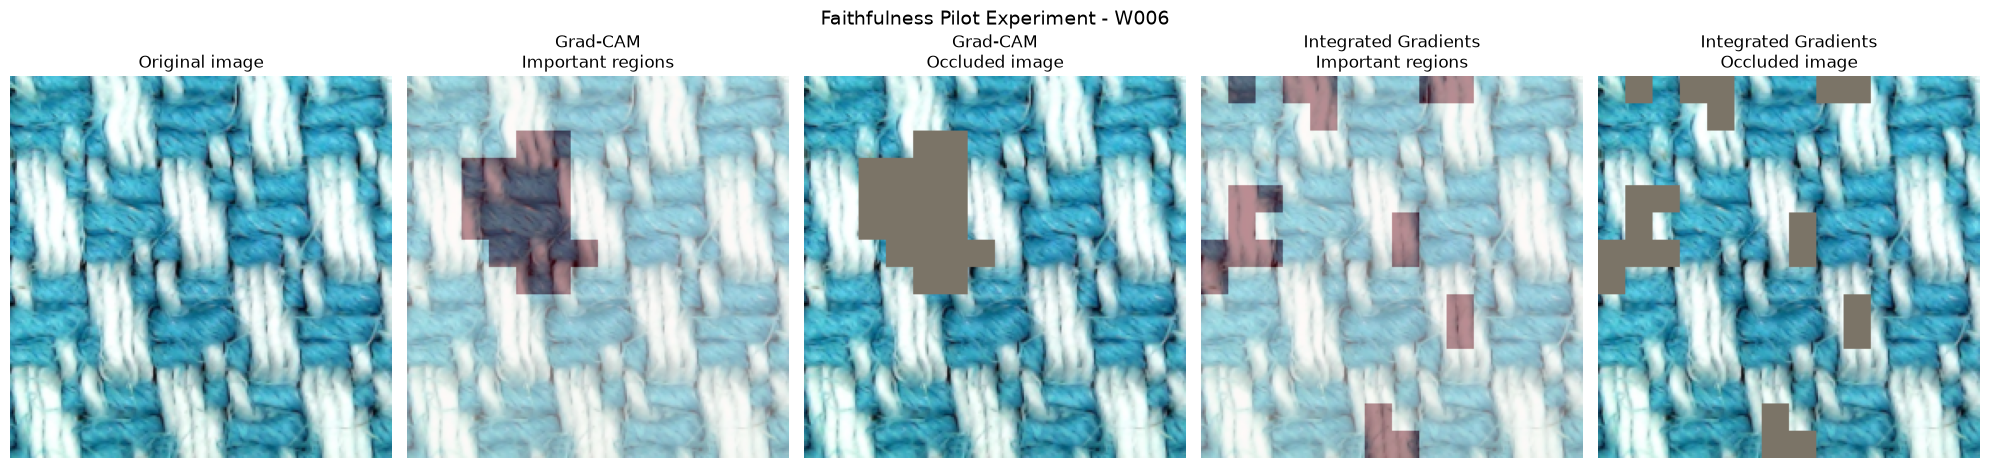

In [6]:
# ==========================================
# 6. PILOT OCCLUSION EXPERIMENT - W006
# ==========================================

import matplotlib.pyplot as plt

# ------------------------------------------
# Experiment configuration
# ------------------------------------------

IMAGE_SIZE = 224
PATCH_SIZE = 16
GRID_SIZE = IMAGE_SIZE // PATCH_SIZE

TOP_PATCH_COUNT = 20
N_RANDOM_MASKS = 5
OCCLUSION_VALUE = 0.0

assert IMAGE_SIZE % PATCH_SIZE == 0

TOTAL_PATCHES = GRID_SIZE * GRID_SIZE

print("Image grid:", GRID_SIZE, "x", GRID_SIZE)
print("Total patches:", TOTAL_PATCHES)
print("Selected important patches:", TOP_PATCH_COUNT)
print("Occluded image percentage:",
      round(TOP_PATCH_COUNT / TOTAL_PATCHES * 100, 2), "%")


# ------------------------------------------
# 1. Calculate average importance per patch
# ------------------------------------------

def calculate_patch_scores(attribution_map):

    if attribution_map.shape != (IMAGE_SIZE, IMAGE_SIZE):
        raise ValueError(
            f"Unexpected attribution shape: {attribution_map.shape}"
        )

    patch_scores = attribution_map.reshape(
        GRID_SIZE,
        PATCH_SIZE,
        GRID_SIZE,
        PATCH_SIZE
    ).mean(axis=(1, 3))

    return patch_scores


# ------------------------------------------
# 2. Convert selected patches into a mask
# ------------------------------------------

def create_patch_mask(patch_indices):

    mask = np.zeros(
        (IMAGE_SIZE, IMAGE_SIZE),
        dtype=bool
    )

    for index in patch_indices:

        row, col = divmod(int(index), GRID_SIZE)

        y_start = row * PATCH_SIZE
        y_end = y_start + PATCH_SIZE

        x_start = col * PATCH_SIZE
        x_end = x_start + PATCH_SIZE

        mask[y_start:y_end, x_start:x_end] = True

    return mask


# ------------------------------------------
# 3. Hide selected patches
# ------------------------------------------

def occlude_image(image_tensor, patch_indices):

    occluded = image_tensor.clone()

    mask = create_patch_mask(patch_indices)

    mask_tensor = torch.from_numpy(mask).to(DEVICE)

    occluded[:, :, mask_tensor] = OCCLUSION_VALUE

    return occluded


# ------------------------------------------
# 4. Predict target-class confidence
# ------------------------------------------

def get_prediction_confidence(model, image_tensor, target_index):

    with torch.inference_mode():

        logits = model(image_tensor)

        probabilities = torch.softmax(logits, dim=1)

        target_confidence = probabilities[0, target_index].item()

        predicted_index = probabilities.argmax(dim=1).item()

    return {
        "target_confidence": target_confidence,
        "predicted_class": CLASS_NAMES[predicted_index]
    }


# ------------------------------------------
# 5. Load W006 and its corresponding model
# ------------------------------------------

sample_row = faithfulness_df.loc[
    faithfulness_df["image_filename"] == "W006.jpg"
].iloc[0]

sample_image = Image.open(
    sample_row["image_path"]
).convert("RGB")

input_tensor = transform(sample_image).unsqueeze(0).to(DEVICE)

fold = int(sample_row["fold"])
model = models_by_fold[fold]

target_class = sample_row["predicted_class"]
target_index = CLASS_NAMES.index(target_class)

original_result = get_prediction_confidence(
    model,
    input_tensor,
    target_index
)

original_confidence = original_result["target_confidence"]

print("\n--- Original prediction ---")
print("Image:", sample_row["image_filename"])
print("Fold:", fold)
print("Actual class:", sample_row["actual_class"])
print("Target class:", target_class)
print("Original confidence:", round(original_confidence, 6))


# ------------------------------------------
# 6. Generate reproducible random masks
# ------------------------------------------

image_number = int(
    sample_row["image_filename"].replace("W", "").replace(".jpg", "")
)

rng = np.random.default_rng(SEED + image_number)

random_masks = [
    rng.choice(
        TOTAL_PATCHES,
        size=TOP_PATCH_COUNT,
        replace=False
    )
    for _ in range(N_RANDOM_MASKS)
]


# ------------------------------------------
# 7. Run Grad-CAM and IG occlusion
# ------------------------------------------

attribution_maps = {
    "Grad-CAM": np.load(sample_row["gradcam_path"]),
    "Integrated Gradients": np.load(sample_row["ig_path"])
}

pilot_rows = []
visualization_data = {}

for method, attribution_map in attribution_maps.items():

    # Calculate importance scores
    patch_scores = calculate_patch_scores(attribution_map)

    # Select highest-importance patches
    important_indices = np.argsort(
        patch_scores.ravel()
    )[-TOP_PATCH_COUNT:][::-1]

    visualization_data[method] = important_indices

    # Occlude the important patches
    important_image = occlude_image(
        input_tensor,
        important_indices
    )

    important_result = get_prediction_confidence(
        model,
        important_image,
        target_index
    )

    pilot_rows.append({
        "image_filename": "W006.jpg",
        "method": method,
        "occlusion_type": "important",
        "repeat": 0,
        "target_class": target_class,
        "predicted_class_after": important_result["predicted_class"],
        "confidence_before": original_confidence,
        "confidence_after": important_result["target_confidence"],
        "confidence_drop_pp": (
            original_confidence
            - important_result["target_confidence"]
        ) * 100
    })

    # Occlude random patches
    for repeat, random_indices in enumerate(random_masks, start=1):

        random_image = occlude_image(
            input_tensor,
            random_indices
        )

        random_result = get_prediction_confidence(
            model,
            random_image,
            target_index
        )

        pilot_rows.append({
            "image_filename": "W006.jpg",
            "method": method,
            "occlusion_type": "random",
            "repeat": repeat,
            "target_class": target_class,
            "predicted_class_after": random_result["predicted_class"],
            "confidence_before": original_confidence,
            "confidence_after": random_result["target_confidence"],
            "confidence_drop_pp": (
                original_confidence
                - random_result["target_confidence"]
            ) * 100
        })


# ------------------------------------------
# 8. Display pilot experiment results
# ------------------------------------------

pilot_results_df = pd.DataFrame(pilot_rows)

print("\n--- W006 pilot results ---")

display(
    pilot_results_df.round(4)
)

print("\n--- Average confidence drop ---")

display(
    pilot_results_df.groupby(
        ["method", "occlusion_type"]
    )["confidence_drop_pp"]
    .agg(["mean", "std", "count"])
    .round(3)
)


# ------------------------------------------
# 9. Visualize the important occluded regions
# ------------------------------------------

def denormalize_image(image_tensor):

    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    image = (
        image_tensor.detach()
        .cpu()
        .squeeze(0)
        .permute(1, 2, 0)
        .numpy()
    )

    image = image * std + mean

    return np.clip(image, 0, 1)


original_display = denormalize_image(input_tensor)

fig, axes = plt.subplots(1, 5, figsize=(20, 5))

axes[0].imshow(original_display)
axes[0].set_title("Original image")
axes[0].axis("off")

for method, start_index in [
    ("Grad-CAM", 1),
    ("Integrated Gradients", 3)
]:

    indices = visualization_data[method]

    mask = create_patch_mask(indices)

    # Show selected important regions
    axes[start_index].imshow(original_display)
    axes[start_index].imshow(
        mask,
        cmap="Reds",
        alpha=0.45
    )
    axes[start_index].set_title(
        f"{method}\nImportant regions"
    )
    axes[start_index].axis("off")

    # Show occluded image
    occluded_tensor = occlude_image(
        input_tensor,
        indices
    )

    occluded_display = denormalize_image(
        occluded_tensor
    )

    axes[start_index + 1].imshow(occluded_display)
    axes[start_index + 1].set_title(
        f"{method}\nOccluded image"
    )
    axes[start_index + 1].axis("off")

plt.suptitle(
    "Faithfulness Pilot Experiment - W006",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [7]:
pilot_summary = (
    pilot_results_df
    .groupby(
        ["method", "occlusion_type"],
        as_index=False
    )
    .agg(
        mean_confidence_drop_pp=("confidence_drop_pp", "mean"),
        std_confidence_drop_pp=("confidence_drop_pp", "std"),
        number_of_trials=("confidence_drop_pp", "count")
    )
)

display(pilot_summary.round(4))

,method,occlusion_type,mean_confidence_drop_pp,std_confidence_drop_pp,number_of_trials
0,Grad-CAM,important,-0.7374,NaN,1
1,Grad-CAM,random,3.2138,2.3886,5
2,Integrated Gradients,important,2.1455,NaN,1
3,Integrated Gradients,random,3.2138,2.3886,5


Run the full 130-image faithfulness experiment

In [8]:
# ==========================================
# 7. FULL FAITHFULNESS ANALYSIS
# ==========================================

import time

# Output file
FAITHFULNESS_RESULTS_PATH = (
    OUTPUT_DIR / "faithfulness_results.csv"
)

# Experiment settings
METHODS = ["Grad-CAM", "Integrated Gradients"]

print("Starting full faithfulness experiment...")
print("Number of images:", len(faithfulness_df))
print("Device:", DEVICE)

full_results = []
start_time = time.time()

# Process all 130 images
for image_number, (_, row) in enumerate(
    faithfulness_df.iterrows(), start=1
):

    filename = row["image_filename"]
    fold = int(row["fold"])

    model = models_by_fold[fold]

    # Original predicted class is the target
    target_class = row["model_predicted_class"]
    target_index = CLASS_NAMES.index(target_class)

    original_confidence = float(row["model_confidence"])

    # --------------------------------------
    # 1. Load and preprocess original image
    # --------------------------------------

    with Image.open(row["image_path"]) as image:
        image = image.convert("RGB")
        input_tensor = transform(image).unsqueeze(0).to(DEVICE)

    # --------------------------------------
    # 2. Generate important-region masks
    # --------------------------------------

    important_masks = {}

    for method, map_path in [
        ("Grad-CAM", row["gradcam_path"]),
        ("Integrated Gradients", row["ig_path"])
    ]:

        attribution_map = np.load(map_path)

        patch_scores = calculate_patch_scores(
            attribution_map
        )

        important_indices = np.argsort(
            patch_scores.ravel()
        )[-TOP_PATCH_COUNT:][::-1]

        important_masks[method] = important_indices

    # --------------------------------------
    # 3. Generate five shared random masks
    # --------------------------------------

    numeric_image_id = int(
        Path(filename).stem.replace("W", "")
    )

    rng = np.random.default_rng(
        SEED + numeric_image_id
    )

    random_masks = [
        rng.choice(
            TOTAL_PATCHES,
            size=TOP_PATCH_COUNT,
            replace=False
        )
        for _ in range(N_RANDOM_MASKS)
    ]

    # --------------------------------------
    # 4. Create seven distinct occluded images
    # --------------------------------------

    occluded_tensors = []

    # First: Grad-CAM important regions
    occluded_tensors.append(
        occlude_image(
            input_tensor,
            important_masks["Grad-CAM"]
        )
    )

    # Second: Integrated Gradients important regions
    occluded_tensors.append(
        occlude_image(
            input_tensor,
            important_masks["Integrated Gradients"]
        )
    )

    # Remaining five: shared random masks
    for random_indices in random_masks:

        occluded_tensors.append(
            occlude_image(
                input_tensor,
                random_indices
            )
        )

    # Combine into one batch
    occluded_batch = torch.cat(
        occluded_tensors,
        dim=0
    )

    # --------------------------------------
    # 5. Evaluate all seven images
    # --------------------------------------

    with torch.inference_mode():

        logits = model(occluded_batch)

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        target_confidences = (
            probabilities[:, target_index]
            .cpu()
            .numpy()
        )

        predicted_indices = (
            probabilities.argmax(dim=1)
            .cpu()
            .numpy()
        )

    # --------------------------------------
    # 6. Record Grad-CAM and IG results
    # --------------------------------------

    for method, result_index in [
        ("Grad-CAM", 0),
        ("Integrated Gradients", 1)
    ]:

        confidence_after = float(
            target_confidences[result_index]
        )

        predicted_after = CLASS_NAMES[
            predicted_indices[result_index]
        ]

        full_results.append({
            "image_filename": filename,
            "actual_class": row["actual_class"],
            "fold": fold,
            "method": method,
            "occlusion_type": "important",
            "repeat": 0,
            "target_class": target_class,
            "predicted_class_after": predicted_after,
            "confidence_before": original_confidence,
            "confidence_after": confidence_after,
            "confidence_drop_pp": (
                original_confidence - confidence_after
            ) * 100,
            "prediction_changed": (
                predicted_after != target_class
            )
        })

        # Add five random controls
        for random_number in range(N_RANDOM_MASKS):

            result_index = random_number + 2

            confidence_after = float(
                target_confidences[result_index]
            )

            predicted_after = CLASS_NAMES[
                predicted_indices[result_index]
            ]

            full_results.append({
                "image_filename": filename,
                "actual_class": row["actual_class"],
                "fold": fold,
                "method": method,
                "occlusion_type": "random",
                "repeat": random_number + 1,
                "target_class": target_class,
                "predicted_class_after": predicted_after,
                "confidence_before": original_confidence,
                "confidence_after": confidence_after,
                "confidence_drop_pp": (
                    original_confidence - confidence_after
                ) * 100,
                "prediction_changed": (
                    predicted_after != target_class
                )
            })

    # --------------------------------------
    # 7. Save progress every 10 images
    # --------------------------------------

    if image_number % 10 == 0 or image_number == len(faithfulness_df):

        progress_df = pd.DataFrame(full_results)

        progress_df.to_csv(
            FAITHFULNESS_RESULTS_PATH,
            index=False
        )

        print(
            f"Processed {image_number}/{len(faithfulness_df)} images | "
            f"Records: {len(full_results)}"
        )

# ------------------------------------------
# 8. Final results
# ------------------------------------------

faithfulness_results_df = pd.DataFrame(
    full_results
)

elapsed_minutes = (time.time() - start_time) / 60

print("\n====================================")
print("FAITHFULNESS EXPERIMENT COMPLETED")
print("====================================")

print("Images processed:", image_number)
print("Total experiment records:", len(faithfulness_results_df))
print("Unique images:", faithfulness_results_df["image_filename"].nunique())
print("Execution time (minutes):", round(elapsed_minutes, 2))

print("\nResults saved to:")
print(FAITHFULNESS_RESULTS_PATH)

# ------------------------------------------
# 9. Validate experiment completeness
# ------------------------------------------

expected_records = (
    len(faithfulness_df)
    * len(METHODS)
    * (1 + N_RANDOM_MASKS)
)

assert len(faithfulness_results_df) == expected_records
assert faithfulness_results_df["image_filename"].nunique() == 130

print("\nAll expected experiment records generated.")

display(faithfulness_results_df.head(10))

Starting full faithfulness experiment...
Number of images: 130
Device: cpu
Processed 10/130 images | Records: 120
Processed 20/130 images | Records: 240
Processed 30/130 images | Records: 360
Processed 40/130 images | Records: 480
Processed 50/130 images | Records: 600
Processed 60/130 images | Records: 720
Processed 70/130 images | Records: 840
Processed 80/130 images | Records: 960
Processed 90/130 images | Records: 1080
Processed 100/130 images | Records: 1200
Processed 110/130 images | Records: 1320
Processed 120/130 images | Records: 1440
Processed 130/130 images | Records: 1560

FAITHFULNESS EXPERIMENT COMPLETED
Images processed: 130
Total experiment records: 1560
Unique images: 130
Execution time (minutes): 0.21

Results saved to:
D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\metrics\faithfulness_analysis\faithfulness_results.csv

All expected experiment records generated.


,image_filename,actual_class,fold,method,occlusion_type,repeat,target_class,predicted_class_after,confidence_before,confidence_after,confidence_drop_pp,prediction_changed
0,W006.jpg,twill,1,Grad-CAM,important,0,twill,twill,0.970566,0.977940,-0.737423,False
1,W006.jpg,twill,1,Grad-CAM,random,1,twill,twill,0.970566,0.928484,4.208195,False
2,W006.jpg,twill,1,Grad-CAM,random,2,twill,twill,0.970566,0.903436,6.712914,False
3,W006.jpg,twill,1,Grad-CAM,random,3,twill,twill,0.970566,0.950189,2.037662,False
4,W006.jpg,twill,1,Grad-CAM,random,4,twill,twill,0.970566,0.966641,0.392461,False
5,W006.jpg,twill,1,Grad-CAM,random,5,twill,twill,0.970566,0.943388,2.717745,False
6,W006.jpg,twill,1,Integrated Gradients,important,0,twill,twill,0.970566,0.949111,2.145505,False
7,W006.jpg,twill,1,Integrated Gradients,random,1,twill,twill,0.970566,0.928484,4.208195,False
8,W006.jpg,twill,1,Integrated Gradients,random,2,twill,twill,0.970566,0.903436,6.712914,False
9,W006.jpg,twill,1,Integrated Gradients,random,3,twill,twill,0.970566,0.950189,2.037662,False


Validate the full results and calculate the main comparison

In [9]:
# ==========================================
# 8. VALIDATE RESULTS AND COMPARE METHODS
# ==========================================

# Load the saved results
faithfulness_results_df = pd.read_csv(
    FAITHFULNESS_RESULTS_PATH
)

results_df = faithfulness_results_df.copy()

# ------------------------------------------
# 1. Validate experiment completeness
# ------------------------------------------

print("--- Experiment validation ---")

print("Total records:", len(results_df))
print("Unique images:", results_df["image_filename"].nunique())

print("\nRecords by occlusion type:")
print(results_df["occlusion_type"].value_counts())

print("\nRecords by method:")
print(results_df["method"].value_counts())

print("\nRecords by method and occlusion:")
display(
    results_df.groupby(
        ["method", "occlusion_type"]
    ).size().rename("record_count").reset_index()
)

# Check duplicate experiment records
duplicate_count = results_df.duplicated(
    subset=[
        "image_filename",
        "method",
        "occlusion_type",
        "repeat"
    ]
).sum()

# Check missing and non-finite values
numeric_columns = [
    "confidence_before",
    "confidence_after",
    "confidence_drop_pp"
]

missing_values = results_df[numeric_columns].isna().sum()

finite_values = np.isfinite(
    results_df[numeric_columns].to_numpy()
).all()

# Check confidence range
confidence_valid = (
    results_df["confidence_before"].between(0, 1).all()
    and results_df["confidence_after"].between(0, 1).all()
)

# Check each image/method has one important and five random tests
record_counts = (
    results_df.groupby(
        ["image_filename", "method", "occlusion_type"]
    ).size()
)

important_counts_valid = (
    record_counts.xs("important", level="occlusion_type") == 1
).all()

random_counts_valid = (
    record_counts.xs("random", level="occlusion_type") == 5
).all()

print("\nDuplicate records:", duplicate_count)
print("\nMissing numerical values:")
display(missing_values)

print("All numerical values finite:", finite_values)
print("Confidence values within [0, 1]:", confidence_valid)
print("One important test per image/method:", important_counts_valid)
print("Five random tests per image/method:", random_counts_valid)

validation_passed = (
    len(results_df) == 1560
    and results_df["image_filename"].nunique() == 130
    and duplicate_count == 0
    and missing_values.sum() == 0
    and finite_values
    and confidence_valid
    and important_counts_valid
    and random_counts_valid
)

print("\nALL VALIDATION CHECKS PASSED:", validation_passed)

assert validation_passed, "Please investigate the validation failures."

# ------------------------------------------
# 2. Calculate important-region results
# ------------------------------------------

important_summary = (
    results_df[
        results_df["occlusion_type"] == "important"
    ]
    .groupby(
        ["image_filename", "actual_class", "method"],
        as_index=False
    )
    .agg(
        important_confidence_drop_pp=(
            "confidence_drop_pp", "first"
        ),
        important_prediction_changed=(
            "prediction_changed", "first"
        )
    )
)

# ------------------------------------------
# 3. Calculate average random-region results
# ------------------------------------------

random_summary = (
    results_df[
        results_df["occlusion_type"] == "random"
    ]
    .groupby(
        ["image_filename", "actual_class", "method"],
        as_index=False
    )
    .agg(
        random_mean_confidence_drop_pp=(
            "confidence_drop_pp", "mean"
        ),
        random_std_confidence_drop_pp=(
            "confidence_drop_pp", "std"
        ),
        random_prediction_flip_rate=(
            "prediction_changed", "mean"
        )
    )
)

# ------------------------------------------
# 4. Perform paired comparison
# ------------------------------------------

paired_comparison_df = important_summary.merge(
    random_summary,
    on=["image_filename", "actual_class", "method"],
    how="inner",
    validate="one_to_one"
)

# Positive means important occlusion caused a larger drop
paired_comparison_df["faithfulness_advantage_pp"] = (
    paired_comparison_df["important_confidence_drop_pp"]
    - paired_comparison_df["random_mean_confidence_drop_pp"]
)

paired_comparison_df["important_occlusion_better"] = (
    paired_comparison_df["faithfulness_advantage_pp"] > 0
)

print("\nPaired comparisons:", len(paired_comparison_df))

# ------------------------------------------
# 5. Calculate overall method summaries
# ------------------------------------------

overall_summary_rows = []

for method in METHODS:

    method_data = paired_comparison_df[
        paired_comparison_df["method"] == method
    ]

    overall_summary_rows.append({
        "method": method,
        "image_count": len(method_data),

        "important_mean_drop_pp":
            method_data["important_confidence_drop_pp"].mean(),

        "important_std_drop_pp":
            method_data["important_confidence_drop_pp"].std(),

        "random_mean_drop_pp":
            method_data["random_mean_confidence_drop_pp"].mean(),

        "random_std_drop_pp":
            method_data["random_mean_confidence_drop_pp"].std(),

        "mean_faithfulness_advantage_pp":
            method_data["faithfulness_advantage_pp"].mean(),

        "median_faithfulness_advantage_pp":
            method_data["faithfulness_advantage_pp"].median(),

        "images_important_better_pct":
            method_data["important_occlusion_better"].mean() * 100,

        "important_prediction_flip_pct":
            method_data["important_prediction_changed"].mean() * 100,

        "random_prediction_flip_pct":
            method_data["random_prediction_flip_rate"].mean() * 100
    })

overall_faithfulness_summary = pd.DataFrame(
    overall_summary_rows
)

print("\n--- Overall faithfulness comparison ---")

display(
    overall_faithfulness_summary.round(4)
)

# ------------------------------------------
# 6. Save analysis outputs
# ------------------------------------------

OVERALL_SUMMARY_PATH = (
    OUTPUT_DIR / "faithfulness_summary_overall.csv"
)

PAIRED_COMPARISON_PATH = (
    OUTPUT_DIR / "faithfulness_paired_comparison.csv"
)

overall_faithfulness_summary.to_csv(
    OVERALL_SUMMARY_PATH,
    index=False
)

paired_comparison_df.to_csv(
    PAIRED_COMPARISON_PATH,
    index=False
)

print("\nSaved analysis files:")
print(OVERALL_SUMMARY_PATH)
print(PAIRED_COMPARISON_PATH)

--- Experiment validation ---
Total records: 1560
Unique images: 130

Records by occlusion type:
occlusion_type
random       1300
important     260
Name: count, dtype: int64

Records by method:
method
Grad-CAM                780
Integrated Gradients    780
Name: count, dtype: int64

Records by method and occlusion:


,method,occlusion_type,record_count
0,Grad-CAM,important,130
1,Grad-CAM,random,650
2,Integrated Gradients,important,130
3,Integrated Gradients,random,650



Duplicate records: 0

Missing numerical values:


confidence_before     0
confidence_after      0
confidence_drop_pp    0
dtype: int64

All numerical values finite: True
Confidence values within [0, 1]: True
One important test per image/method: True
Five random tests per image/method: True

ALL VALIDATION CHECKS PASSED: True

Paired comparisons: 260

--- Overall faithfulness comparison ---


,method,image_count,important_mean_drop_pp,important_std_drop_pp,random_mean_drop_pp,random_std_drop_pp,mean_faithfulness_advantage_pp,median_faithfulness_advantage_pp,images_important_better_pct,important_prediction_flip_pct,random_prediction_flip_pct
0,Grad-CAM,130,5.3981,10.9280,5.7478,14.1449,-0.3497,0.0088,50.0000,3.0769,8.9231
1,Integrated Gradients,130,5.3121,14.5639,5.7478,14.1449,-0.4357,-0.0616,46.1538,6.9231,8.9231



Saved analysis files:
D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\metrics\faithfulness_analysis\faithfulness_summary_overall.csv
D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\metrics\faithfulness_analysis\faithfulness_paired_comparison.csv


Compare faithfulness across fabric classes

In [10]:
# ==========================================
# 9. CLASS-WISE FAITHFULNESS ANALYSIS
# ==========================================

class_faithfulness_summary = (
    paired_comparison_df
    .groupby(
        ["actual_class", "method"],
        as_index=False
    )
    .agg(
        image_count=("image_filename", "nunique"),

        important_mean_drop_pp=(
            "important_confidence_drop_pp", "mean"
        ),

        important_std_drop_pp=(
            "important_confidence_drop_pp", "std"
        ),

        random_mean_drop_pp=(
            "random_mean_confidence_drop_pp", "mean"
        ),

        random_std_drop_pp=(
            "random_mean_confidence_drop_pp", "std"
        ),

        mean_faithfulness_advantage_pp=(
            "faithfulness_advantage_pp", "mean"
        ),

        median_faithfulness_advantage_pp=(
            "faithfulness_advantage_pp", "median"
        ),

        images_important_better_pct=(
            "important_occlusion_better", "mean"
        ),

        important_prediction_flip_pct=(
            "important_prediction_changed", "mean"
        ),

        random_prediction_flip_pct=(
            "random_prediction_flip_rate", "mean"
        )
    )
)

# Convert proportions to percentages
for column in [
    "images_important_better_pct",
    "important_prediction_flip_pct",
    "random_prediction_flip_pct"
]:
    class_faithfulness_summary[column] *= 100

# Arrange classes in the expected order
class_order = ["plain", "satin", "twill"]

class_faithfulness_summary["actual_class"] = pd.Categorical(
    class_faithfulness_summary["actual_class"].str.lower(),
    categories=class_order,
    ordered=True
)

class_faithfulness_summary = (
    class_faithfulness_summary
    .sort_values(["actual_class", "method"])
    .reset_index(drop=True)
)

# Display results
print("--- Class-wise faithfulness comparison ---")

display(
    class_faithfulness_summary.round(4)
)

# Save results
CLASS_SUMMARY_PATH = (
    OUTPUT_DIR / "faithfulness_summary_by_class.csv"
)

class_faithfulness_summary.to_csv(
    CLASS_SUMMARY_PATH,
    index=False
)

print("\nClass-wise summary saved to:")
print(CLASS_SUMMARY_PATH)

print("\nOriginal image counts by class:")

display(
    paired_comparison_df[
        ["image_filename", "actual_class"]
    ]
    .drop_duplicates()
    ["actual_class"]
    .value_counts()
    .reindex(class_order)
)

--- Class-wise faithfulness comparison ---


,actual_class,method,image_count,important_mean_drop_pp,important_std_drop_pp,random_mean_drop_pp,random_std_drop_pp,mean_faithfulness_advantage_pp,median_faithfulness_advantage_pp,images_important_better_pct,important_prediction_flip_pct,random_prediction_flip_pct
0,plain,Grad-CAM,50,7.3641,11.7404,8.8375,15.9551,-1.4734,0.0237,50.0000,2.0000,8.8000
1,plain,Integrated Gradients,50,7.5417,16.4669,8.8375,15.9551,-1.2959,0.0895,52.0000,6.0000,8.8000
2,satin,Grad-CAM,41,5.8253,8.7699,7.1123,12.0210,-1.2871,-0.3839,43.9024,4.8780,13.1707
3,satin,Integrated Gradients,41,6.1229,10.2697,7.1123,12.0210,-0.9894,-0.2566,39.0244,9.7561,13.1707
4,twill,Grad-CAM,39,2.4285,11.5053,0.3520,12.4255,2.0765,0.2430,56.4103,2.5641,4.6154
5,twill,Integrated Gradients,39,1.6014,15.4271,0.3520,12.4255,1.2493,-0.3309,46.1538,5.1282,4.6154



Class-wise summary saved to:
D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\metrics\faithfulness_analysis\faithfulness_summary_by_class.csv

Original image counts by class:


actual_class
plain    50
satin    41
twill    39
Name: count, dtype: int64

There appears to be a difference between fabric classes:
- Plain and Satin: random-region occlusion has a larger average effect.
- Twill: important-region occlusion has a larger average effect.
This suggests that faithfulness behaviour may depend on the fabric structure being classified.

However, these are currently descriptive observations. We have not yet established whether the differences are statistically significant.

One important detail: the class-wise grouping uses the actual fabric class, while the confidence drop measures the original predicted class. We are testing the influence of the explanation on the model's original prediction, not directly measuring correctness.

Test whether the differences are statistically meaningful

In [11]:
# ==========================================
# 10. PAIRED STATISTICAL TESTS
# ==========================================

from scipy.stats import wilcoxon, rankdata

# Positive difference means important-region occlusion
# produces a larger confidence drop than random occlusion.

def run_paired_wilcoxon(data, method, class_name="all"):

    differences = (
        data["faithfulness_advantage_pp"]
        .to_numpy(dtype=float)
    )

    differences = differences[np.isfinite(differences)]

    n = len(differences)

    if n == 0:
        raise ValueError("No valid paired observations.")

    nonzero = differences[differences != 0]

    if len(nonzero) == 0:
        p_value = 1.0
        statistic = 0.0
        rank_biserial = 0.0

    else:
        test_result = wilcoxon(
            differences,
            zero_method="wilcox",
            alternative="two-sided",
            method="auto"
        )

        statistic = test_result.statistic
        p_value = test_result.pvalue

        # Matched-pairs rank-biserial effect size
        ranks = rankdata(np.abs(nonzero))

        positive_rank_sum = ranks[nonzero > 0].sum()
        negative_rank_sum = ranks[nonzero < 0].sum()

        rank_biserial = (
            positive_rank_sum - negative_rank_sum
        ) / (positive_rank_sum + negative_rank_sum)

    return {
        "scope": class_name,
        "method": method,
        "image_count": n,
        "mean_advantage_pp": differences.mean(),
        "median_advantage_pp": np.median(differences),
        "positive_advantage_pct": (
            (differences > 0).mean() * 100
        ),
        "wilcoxon_statistic": statistic,
        "p_value": p_value,
        "rank_biserial_effect": rank_biserial
    }


# ------------------------------------------
# 1. Overall statistical tests
# ------------------------------------------

overall_tests = []

for method in METHODS:

    method_data = paired_comparison_df[
        paired_comparison_df["method"] == method
    ]

    overall_tests.append(
        run_paired_wilcoxon(
            method_data,
            method,
            class_name="Overall"
        )
    )

overall_tests_df = pd.DataFrame(overall_tests)


# ------------------------------------------
# 2. Class-wise statistical tests
# ------------------------------------------

class_tests = []

for fabric_class in ["plain", "satin", "twill"]:

    for method in METHODS:

        class_data = paired_comparison_df[
            (
                paired_comparison_df["actual_class"].astype(str).str.lower()
                == fabric_class
            )
            & (
                paired_comparison_df["method"] == method
            )
        ]

        class_tests.append(
            run_paired_wilcoxon(
                class_data,
                method,
                class_name=fabric_class.capitalize()
            )
        )

class_tests_df = pd.DataFrame(class_tests)


# ------------------------------------------
# 3. Holm multiple-testing correction
# ------------------------------------------

def holm_adjust(p_values):

    p_values = np.asarray(p_values, dtype=float)

    m = len(p_values)

    sorted_indices = np.argsort(p_values)
    sorted_p_values = p_values[sorted_indices]

    adjusted_sorted = np.maximum.accumulate(
        (m - np.arange(m)) * sorted_p_values
    )

    adjusted_sorted = np.minimum(adjusted_sorted, 1.0)

    adjusted = np.empty(m)
    adjusted[sorted_indices] = adjusted_sorted

    return adjusted


# Correct the six class-wise tests together
class_tests_df["holm_adjusted_p"] = holm_adjust(
    class_tests_df["p_value"]
)

# Correct the two overall tests together
overall_tests_df["holm_adjusted_p"] = holm_adjust(
    overall_tests_df["p_value"]
)


# ------------------------------------------
# 4. Display results
# ------------------------------------------

print("--- Overall paired statistical tests ---")

display(
    overall_tests_df.round(5)
)

print("\n--- Class-wise paired statistical tests ---")

display(
    class_tests_df.round(5)
)


# ------------------------------------------
# 5. Save statistical results
# ------------------------------------------

OVERALL_TEST_PATH = (
    OUTPUT_DIR / "faithfulness_statistical_tests_overall.csv"
)

CLASS_TEST_PATH = (
    OUTPUT_DIR / "faithfulness_statistical_tests_by_class.csv"
)

overall_tests_df.to_csv(
    OVERALL_TEST_PATH,
    index=False
)

class_tests_df.to_csv(
    CLASS_TEST_PATH,
    index=False
)

print("\nStatistical test results saved:")
print(OVERALL_TEST_PATH)
print(CLASS_TEST_PATH)

--- Overall paired statistical tests ---


,scope,method,image_count,mean_advantage_pp,median_advantage_pp,positive_advantage_pct,wilcoxon_statistic,p_value,rank_biserial_effect,holm_adjusted_p
0,Overall,Grad-CAM,130,-0.34967,0.00881,50.00000,4221.0,0.93241,-0.00857,1.0
1,Overall,Integrated Gradients,130,-0.43566,-0.06159,46.15385,4065.0,0.65465,-0.04521,1.0



--- Class-wise paired statistical tests ---


,scope,method,image_count,mean_advantage_pp,median_advantage_pp,positive_advantage_pct,wilcoxon_statistic,p_value,rank_biserial_effect,holm_adjusted_p
0,Plain,Grad-CAM,50,-1.47342,0.02366,50.00000,618.0,0.85575,-0.03059,1.0000
1,Plain,Integrated Gradients,50,-1.29586,0.08953,52.00000,618.0,0.85575,-0.03059,1.0000
2,Satin,Grad-CAM,41,-1.28705,-0.38392,43.90244,322.0,0.16330,-0.25203,0.9798
3,Satin,Integrated Gradients,41,-0.98944,-0.25663,39.02439,355.0,0.33478,-0.17538,1.0000
4,Twill,Grad-CAM,39,2.07650,0.24296,56.41026,315.0,0.30211,0.19231,1.0000
5,Twill,Integrated Gradients,39,1.24933,-0.33094,46.15385,376.0,0.85224,0.03590,1.0000



Statistical test results saved:
D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\metrics\faithfulness_analysis\faithfulness_statistical_tests_overall.csv
D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\metrics\faithfulness_analysis\faithfulness_statistical_tests_by_class.csv


Create and save the final visualizations

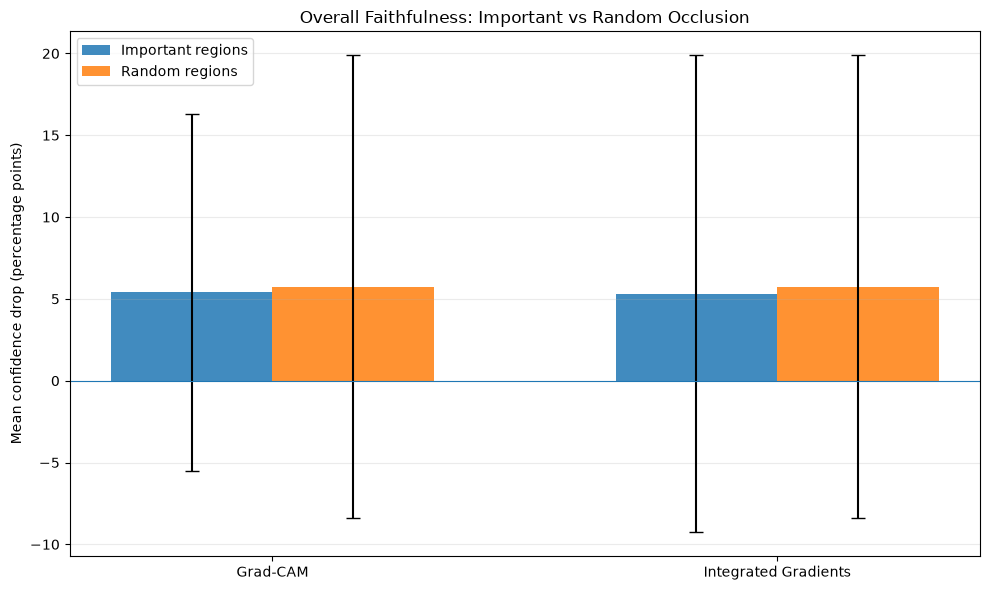

Saved: D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\figures\faithfulness_overall_comparison.png


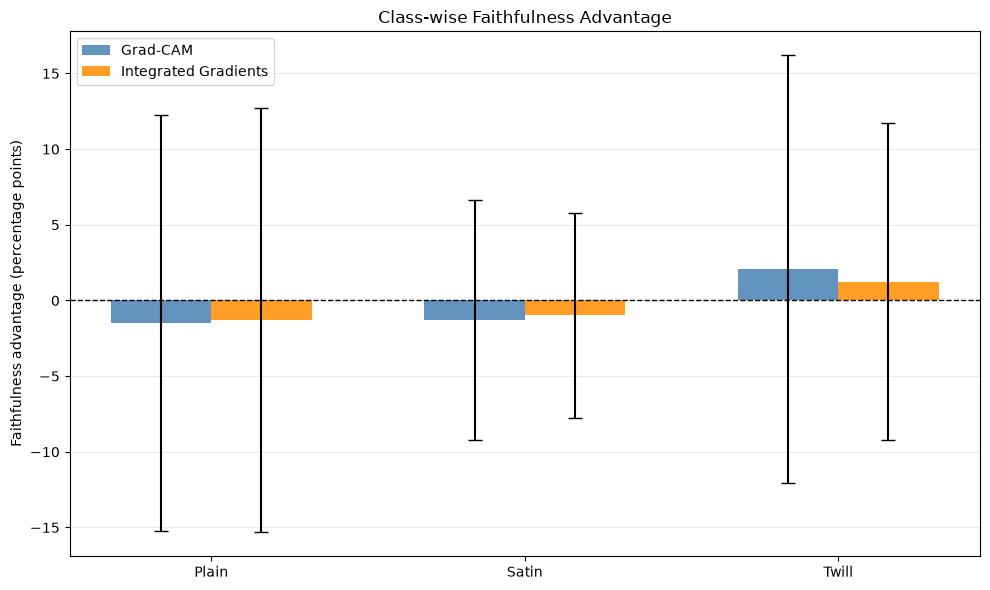

Saved: D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\figures\faithfulness_classwise_advantage.png


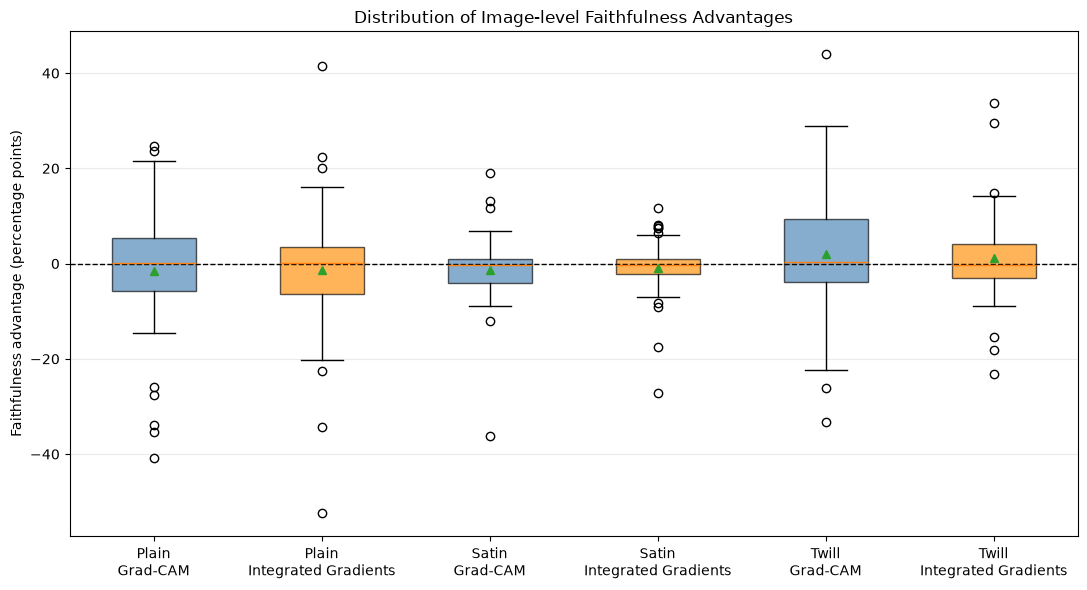

Saved: D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\figures\faithfulness_advantage_distribution.png


In [13]:
# ==========================================
# 11. FAITHFULNESS VISUALIZATIONS
# ==========================================

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

method_order = ["Grad-CAM", "Integrated Gradients"]
class_order = ["plain", "satin", "twill"]

# Consistent visual settings
method_colors = {
    "Grad-CAM": "steelblue",
    "Integrated Gradients": "darkorange"
}

# ------------------------------------------
# FIGURE 1: Overall confidence-drop comparison
# ------------------------------------------

plot_rows = []

for method in method_order:

    method_data = paired_comparison_df[
        paired_comparison_df["method"] == method
    ]

    plot_rows.append({
        "method": method,
        "occlusion": "Important regions",
        "mean": method_data[
            "important_confidence_drop_pp"
        ].mean(),
        "std": method_data[
            "important_confidence_drop_pp"
        ].std()
    })

    plot_rows.append({
        "method": method,
        "occlusion": "Random regions",
        "mean": method_data[
            "random_mean_confidence_drop_pp"
        ].mean(),
        "std": method_data[
            "random_mean_confidence_drop_pp"
        ].std()
    })

overall_plot_df = pd.DataFrame(plot_rows)

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(method_order))
width = 0.32

for i, occlusion in enumerate([
    "Important regions",
    "Random regions"
]):

    subset = (
        overall_plot_df[
            overall_plot_df["occlusion"] == occlusion
        ]
        .set_index("method")
        .reindex(method_order)
    )

    positions = x + (i - 0.5) * width

    ax.bar(
        positions,
        subset["mean"],
        width,
        yerr=subset["std"],
        capsize=5,
        label=occlusion,
        alpha=0.85
    )

ax.axhline(0, linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(method_order)
ax.set_ylabel("Mean confidence drop (percentage points)")
ax.set_title("Overall Faithfulness: Important vs Random Occlusion")
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

figure1_path = (
    FIGURES_DIR / "faithfulness_overall_comparison.png"
)

plt.savefig(
    figure1_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Saved:", figure1_path)


# ------------------------------------------
# FIGURE 2: Class-wise faithfulness advantage
# ------------------------------------------

class_plot_df = (
    paired_comparison_df
    .groupby(
        ["actual_class", "method"]
    )["faithfulness_advantage_pp"]
    .agg(["mean", "std"])
    .reset_index()
)

class_plot_df["actual_class"] = (
    class_plot_df["actual_class"].str.lower()
)

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(class_order))
width = 0.32

for i, method in enumerate(method_order):

    subset = (
        class_plot_df[
            class_plot_df["method"] == method
        ]
        .set_index("actual_class")
        .reindex(class_order)
    )

    positions = x + (i - 0.5) * width

    ax.bar(
        positions,
        subset["mean"],
        width,
        yerr=subset["std"],
        capsize=5,
        label=method,
        alpha=0.85,
        color=method_colors[method]
    )

ax.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_xticks(x)
ax.set_xticklabels(["Plain", "Satin", "Twill"])
ax.set_ylabel("Faithfulness advantage (percentage points)")
ax.set_title("Class-wise Faithfulness Advantage")
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

figure2_path = (
    FIGURES_DIR / "faithfulness_classwise_advantage.png"
)

plt.savefig(
    figure2_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Saved:", figure2_path)


# ==========================================
# FIGURE 3: DISTRIBUTION OF PAIRED ADVANTAGES
# ==========================================

fig, ax = plt.subplots(figsize=(11, 6))

box_data = []
box_labels = []
box_colors = []

for fabric_class in class_order:

    for method in method_order:

        values = paired_comparison_df.loc[
            (
                paired_comparison_df["actual_class"].str.lower()
                == fabric_class
            )
            & (
                paired_comparison_df["method"] == method
            ),
            "faithfulness_advantage_pp"
        ].values

        box_data.append(values)

        box_labels.append(
            f"{fabric_class.capitalize()}\n{method}"
        )

        box_colors.append(method_colors[method])


# Create boxplot without labels argument
boxplot = ax.boxplot(
    box_data,
    patch_artist=True,
    showmeans=True
)

# Apply colors
for patch, color in zip(
    boxplot["boxes"],
    box_colors
):
    patch.set_facecolor(color)
    patch.set_alpha(0.65)

# Set labels separately (version-compatible)
ax.set_xticks(range(1, len(box_labels) + 1))
ax.set_xticklabels(box_labels)

# Reference line
ax.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_ylabel("Faithfulness advantage (percentage points)")
ax.set_title("Distribution of Image-level Faithfulness Advantages")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

figure3_path = (
    FIGURES_DIR / "faithfulness_advantage_distribution.png"
)

plt.savefig(
    figure3_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Saved:", figure3_path)

## 12. Discussion and Conclusion

### Overall Findings

The faithfulness analysis evaluated whether regions identified by Grad-CAM and Integrated Gradients had a greater influence on ResNet-18 predictions than randomly selected image regions. The experiment covered 130 woven fabric images across the Plain, Satin, and Twill classes, using five fold-specific models.

For Grad-CAM, the mean confidence reduction following important-region occlusion was 5.3981 percentage points, compared with 5.7478 percentage points for random-region occlusion. For Integrated Gradients, the corresponding reductions were 5.3121 and 5.7478 percentage points.

The mean paired faithfulness advantages were −0.3497 percentage points for Grad-CAM and −0.4357 percentage points for Integrated Gradients. These results indicate that neither explanation method demonstrated an overall advantage over random-region occlusion.

### Class-wise Findings

The class-wise analysis revealed different descriptive patterns. Plain and Satin showed negative mean faithfulness advantages for both methods, indicating larger average confidence reductions under random-region occlusion. In contrast, Twill showed positive mean advantages of 2.0765 and 1.2493 percentage points for Grad-CAM and Integrated Gradients, respectively.

However, the image-level distributions showed considerable variability, including both positive and negative observations. Therefore, these class-wise differences should be interpreted as descriptive patterns rather than established differences in explanation faithfulness.

### Statistical Analysis

Paired Wilcoxon signed-rank tests were conducted to compare important-region and random-region confidence reductions. Holm correction was applied to account for multiple comparisons.

Neither method demonstrated a statistically significant overall difference. The adjusted p-values were 1.0000 for Grad-CAM and 1.0000 for Integrated Gradients. None of the class-wise comparisons was statistically significant after multiple-testing correction.

The overall rank-biserial effect sizes were −0.0086 for Grad-CAM and −0.0452 for Integrated Gradients, indicating very small overall paired effects.

### Conclusion

Under the selected patch-based occlusion protocol, the experiment did not establish that Grad-CAM or Integrated Gradients consistently identifies image regions that have a greater influence on model confidence than randomly selected regions.

The findings highlight that explanation reliability should not be evaluated solely through visual inspection or stability measurements. Although the explanations generated in the earlier experiments provided spatial attribution patterns, the faithfulness experiment did not demonstrate a consistent advantage over random-region occlusion.

These findings are specific to the selected model, dataset, patch size, masking baseline, and evaluation protocol. Further investigation using alternative occlusion sizes, replacement strategies, and faithfulness evaluation approaches would help provide a broader assessment of explanation reliability.

In [14]:
# ==========================================
# 12. FINAL NOTEBOOK 07 OUTPUT VERIFICATION
# ==========================================

expected_outputs = [
    OUTPUT_DIR / "faithfulness_results.csv",
    OUTPUT_DIR / "faithfulness_summary_overall.csv",
    OUTPUT_DIR / "faithfulness_paired_comparison.csv",
    OUTPUT_DIR / "faithfulness_summary_by_class.csv",
    OUTPUT_DIR / "faithfulness_statistical_tests_overall.csv",
    OUTPUT_DIR / "faithfulness_statistical_tests_by_class.csv",

    FIGURES_DIR / "faithfulness_overall_comparison.png",
    FIGURES_DIR / "faithfulness_classwise_advantage.png",
    FIGURES_DIR / "faithfulness_advantage_distribution.png"
]

print("--- Notebook 07 output verification ---\n")

missing_outputs = []

for path in expected_outputs:

    if path.exists():
        size_kb = path.stat().st_size / 1024
        print(f"FOUND: {path.name} ({size_kb:.2f} KB)")
    else:
        print(f"MISSING: {path.name}")
        missing_outputs.append(path)

print("\nTotal expected outputs:", len(expected_outputs))
print("Files found:", len(expected_outputs) - len(missing_outputs))
print("Files missing:", len(missing_outputs))

if not missing_outputs:
    print("\nSUCCESS: All Notebook 07 outputs are saved.")
else:
    print("\nWARNING: Some outputs need to be saved.")

--- Notebook 07 output verification ---

FOUND: faithfulness_results.csv (178.90 KB)
FOUND: faithfulness_summary_overall.csv (0.60 KB)
FOUND: faithfulness_paired_comparison.csv (31.24 KB)
FOUND: faithfulness_summary_by_class.csv (1.31 KB)
FOUND: faithfulness_statistical_tests_overall.csv (0.41 KB)
FOUND: faithfulness_statistical_tests_by_class.csv (0.91 KB)
FOUND: faithfulness_overall_comparison.png (97.27 KB)
FOUND: faithfulness_classwise_advantage.png (89.76 KB)
FOUND: faithfulness_advantage_distribution.png (155.36 KB)

Total expected outputs: 9
Files found: 9
Files missing: 0

SUCCESS: All Notebook 07 outputs are saved.
